# 3. Gradient Descent Variants - Solution

We continue with the network from last week and implement the three variants of gradient descent from the lecture: stochastic, batch and mini-batch GD.

## Setup
The following cells are the solution of last week's notebook. Just run them.

In [1]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import pandas as pd

X, y = fetch_openml('mnist_784', version=1, return_X_y=True, data_home="./data", cache=True, parser='auto')
y_categorical = pd.get_dummies(y).astype('float32').values
X_scaled = (X/255).astype('float32').values
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_categorical, test_size=0.15, random_state=42)

In [2]:
import time
import numpy as np

class DeepNeuralNetwork():
    def __init__(self):
        
        # initialize weights randomly
        np.random.seed(0)
        self.w1 = np.random.randn(128, 784)
        self.w2 = np.random.randn(64, 128)
        self.w3 = np.random.randn(10, 64)

    def forward_pass(self, x_train):
        z1 = np.dot(self.w1, x_train)
        a1 = 1/(1 + np.exp(-z1)) # sigmoid activation
        z2 = np.dot(self.w2, a1)
        a2 = 1/(1 + np.exp(-z2)) # sigmoid activation
        z3 = np.dot(self.w3, a2)
        exps = np.exp(z3) 
        a3 = exps / exps.sum() # softmax activation
        
        # we need to remember all values for the gradient calculation
        self.fwdpass = [x_train, z1, a1, z2, a2, z3, a3]
        
        return a3
    
    
    def get_gradients(self, y, y_hat):
        # restore values from foward pass
        a0, z1, a1, z2, a2, z3, a3 = self.fwdpass
        
        # Calculate W3 update
        # for softmax + cross-entropy loss, the error at the output simplifies to y_hat - y
        error = y_hat - y
        gradient_w3 = np.outer(error, a2)

        # Calculate W2 update
        sigmoid_derivative = (np.exp(-z2))/((np.exp(-z2)+1)**2)
        error = np.dot(self.w3.T, error) * sigmoid_derivative
        gradient_w2 = np.outer(error, a1)

        # Calculate W1 update
        sigmoid_derivative = (np.exp(-z1))/((np.exp(-z1)+1)**2)
        error = np.dot(self.w2.T, error) * sigmoid_derivative
        gradient_w1 = np.outer(error, a0)

        return [gradient_w1, gradient_w2, gradient_w3]

In [3]:
def evaluate(dnn, X, y):
    predictions = []
    for x, y_true in zip(X, y):
        output = dnn.forward_pass(x)
        pred = np.argmax(output) # returns the index of the neuron with the highest value
        predictions.append(pred == np.argmax(y_true))
    return np.mean(predictions)

dnn = DeepNeuralNetwork()
print("Accuracy of the untrained network:", evaluate(dnn, X_test, y_test))

Accuracy of the untrained network: 0.10238095238095238


This is the training loop from last week (takes about 1 minute):

In [4]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 0.01

start_time = time.time()
losses = []
for iteration in range(no_epochs):
    loss = 0
    for x,y in zip(X_train, y_train):
        y_hat = dnn.forward_pass(x)
        gradients = dnn.get_gradients(y, y_hat)
        
        loss += -np.log(np.dot(y, y_hat))
        
        # one step stochastic gradient descent
        dnn.w1 -= learning_rate * gradients[0]
        dnn.w2 -= learning_rate * gradients[1]
        dnn.w3 -= learning_rate * gradients[2]

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses.append(loss)

Epoch: 1, Time: 21.9s, Loss: 0.6409
Epoch: 2, Time: 41.0s, Loss: 0.3351
Epoch: 3, Time: 58.7s, Loss: 0.2632


## Task 1: Stochastic gradient descent
The loop above does one update per data point, but always visits the data points in the same order. Change it to real SGD: visit the data points in a **random order** in every epoch.

In [5]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 0.01

start_time = time.time()
losses_sgd = []
for iteration in range(no_epochs):
    loss = 0
    order = np.random.permutation(len(X_train))   # random order in every epoch
    print("New order is", order)
    for i in order:
        x, y = X_train[i], y_train[i]
        y_hat = dnn.forward_pass(x)
        gradients = dnn.get_gradients(y, y_hat)

        loss += -np.log(np.dot(y, y_hat))

        # one step stochastic gradient descent
        dnn.w1 -= learning_rate * gradients[0]
        dnn.w2 -= learning_rate * gradients[1]
        dnn.w3 -= learning_rate * gradients[2]

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses_sgd.append(loss)

New order is [19760 17917  6018 ... 52246 20698 15682]
Epoch: 1, Time: 18.1s, Loss: 0.6531
New order is [24245 12637 53664 ... 39321 13565 42676]
Epoch: 2, Time: 35.3s, Loss: 0.3464
New order is [21096 41624  7380 ... 54887 54882 10525]
Epoch: 3, Time: 52.1s, Loss: 0.2759


## Task 2: Batch gradient descent
Do **one** weight update per epoch, using the mean gradient over **all** training data points.

*Check:* the losses should be 8.84, 5.67 and 4.87.

In [6]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 1.0

start_time = time.time()
losses_batch = []
for iteration in range(no_epochs):
    loss = 0
    g1, g2, g3 = 0, 0, 0
    for x, y in zip(X_train, y_train):
        y_hat = dnn.forward_pass(x)
        gradients = dnn.get_gradients(y, y_hat)

        loss += -np.log(np.dot(y, y_hat))

        # sum up the gradients of all data points
        g1 += gradients[0]
        g2 += gradients[1]
        g3 += gradients[2]

    # ONE update per epoch with the mean gradient
    dnn.w1 -= learning_rate * g1 / len(X_train)
    dnn.w2 -= learning_rate * g2 / len(X_train)
    dnn.w3 -= learning_rate * g3 / len(X_train)

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses_batch.append(loss)

Epoch: 1, Time: 14.3s, Loss: 8.8435
Epoch: 2, Time: 29.3s, Loss: 5.6656
Epoch: 3, Time: 44.5s, Loss: 4.8663


## Task 3: Mini-batch gradient descent
Visit the data points in a random order and do one weight update per mini-batch of 64 data points, using the mean gradient of the mini-batch.

In [7]:
dnn = DeepNeuralNetwork()

no_epochs = 3
learning_rate = 0.5
batch_size = 64

start_time = time.time()
losses_mini = []
for iteration in range(no_epochs):
    loss = 0
    order = np.random.permutation(len(X_train))   # random order in every epoch
    for start in range(0, len(X_train), batch_size):
        batch = order[start:start + batch_size]   # indices of the data points in this mini-batch
        g1, g2, g3 = 0, 0, 0
        for i in batch:
            x, y = X_train[i], y_train[i]
            y_hat = dnn.forward_pass(x)
            gradients = dnn.get_gradients(y, y_hat)

            loss += -np.log(np.dot(y, y_hat))

            g1 += gradients[0]
            g2 += gradients[1]
            g3 += gradients[2]

        # one update per mini-batch with the mean gradient of the mini-batch
        dnn.w1 -= learning_rate * g1 / len(batch)
        dnn.w2 -= learning_rate * g2 / len(batch)
        dnn.w3 -= learning_rate * g3 / len(batch)

    loss /= len(X_train) # average loss per sample
    print(f'Epoch: {iteration+1}, Time: {time.time() - start_time:.1f}s, Loss: {loss:.4f}')
    losses_mini.append(loss)

Epoch: 1, Time: 17.4s, Loss: 0.7166
Epoch: 2, Time: 31.3s, Loss: 0.3732
Epoch: 3, Time: 45.4s, Loss: 0.2985


## Task 4: Compare

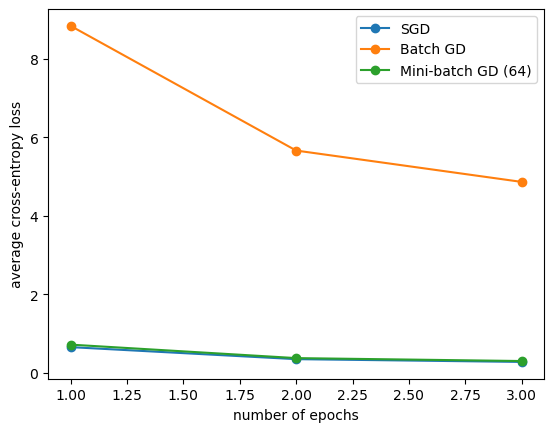

In [8]:
import matplotlib.pyplot as plt
for losses, name in [(losses_sgd, 'SGD'), (losses_batch, 'Batch GD'), (losses_mini, 'Mini-batch GD (64)')]:
    plt.plot(range(1, len(losses) + 1), losses, marker='o', label=name)
plt.xlabel('number of epochs')
plt.ylabel('average cross-entropy loss')
plt.legend()
plt.show()

1. All three variants compute the same number of gradients per epoch (one per data point). Why is batch GD so much worse after 3 epochs?

*Answer:* Batch GD makes only one weight update per epoch (3 in total), SGD ~59,500 and mini-batch GD ~930 per epoch. Many slightly noisy steps make far more progress than a few exact ones, because the training data is redundant: the gradient of a few data points already points roughly in the right direction.

2. Compare the time per epoch of the three variants. Why is it so similar?

*Answer:* All three do the same work per epoch: one forward pass and one gradient calculation per data point. They only differ in how often the weights are updated. The advantage of mini-batches in practice comes from vectorization: all data points of a mini-batch are processed in one matrix operation (as in PyTorch), which is much faster than our loop over single data points.

3. **Bonus:** Run mini-batch GD with the learning rate of SGD (`learning_rate=0.01`). What happens? Why can mini-batch GD use a larger learning rate than SGD?

*Answer:* The loss decreases much more slowly: mini-batch GD makes 64× fewer updates with the same step size. The mean gradient of 64 data points is much less noisy than that of one, so larger steps stay stable.